# Longstaff-Schwartz pricer

Backward induction: at each exercise date, the continuation value is estimated bu a least-squares regression of discounted future cash flows on a polynomial of the spot. This notebook builds the pricer step by step.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt 

from src.rng import LCG
from src.lsm import payoff, basis_matrix, continuation_value

## 1. Building blocks

Payoff, polynomial basis and regression of the continuation value.

In [2]:
K = 100.0
S_test = np.array([80.0, 100.0, 120.0])

print(f"Call payoff :", payoff(S_test, K, "call"))
print(f"Put payoff  :", payoff(S_test, K, "put"))
print("Basis shape  :", basis_matrix(S_test, K, 3).shape)
print(basis_matrix(S_test, K, 3))

Call payoff : [ 0.  0. 20.]
Put payoff  : [20.  0.  0.]
Basis shape  : (3, 4)
[[1.    0.8   0.64  0.512]
 [1.    1.    1.    1.   ]
 [1.    1.2   1.44  1.728]]


In [5]:
# Synthetic test: the true "continuation value" is a known quadratic in x = S / K
n = 5000
z = LCG(seed=1).normal(2 * n)

S = 100 + 20 * z[:n]
x = S / K
true_cont = 1 - 2 * x + 3 * x**2
y = true_cont + 0.01 * z[n:] # small noise

In [6]:
all_paths = np.ones(n, dtype=bool)

for d in [1, 2, 3]:
    fit = continuation_value(S, y, K, d, all_paths)
    print(f"degree {d} | max |fit - truth| = {np.max(np.abs(fit - true_cont)):.5f}")

degree 1 | max |fit - truth| = 1.94389
degree 2 | max |fit - truth| = 0.00169
degree 3 | max |fit - truth| = 0.00229


In [11]:
itm = S < K # in-the-money put
fit_itm = continuation_value(S, y, K, 2, itm)

print("ITM paths        :", itm.sum(), "/", n)
print("NaN outside mask :", np.all(np.isnan(fit_itm[~itm])))
print("No NaN inside    :", not np.any(np.isnan(fit_itm[itm])))

# Not enough points to fit -> everything is NaN
too_few = np.zeros(n, dtype=bool)
too_few[:2] = True
print("Too few points :", np.all(np.isnan(continuation_value(S, y, K, 2, too_few))))

ITM paths        : 2453 / 5000
NaN outside mask : True
No NaN inside    : True
Too few points : True


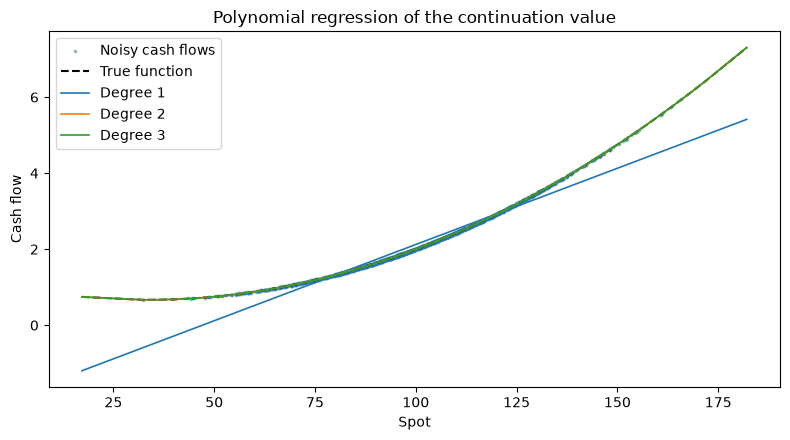

In [12]:
order = np.argsort(S)

plt.figure(figsize=(8, 4.5))
plt.scatter(S[:1500], y[:1500], s=3, alpha=0.4, label="Noisy cash flows")
plt.plot(S[order], true_cont[order], "k--", lw=1.5, label="True function")
for d in [1, 2, 3]:
    fit = continuation_value(S, y, K, d, all_paths)
    plt.plot(S[order], fit[order], lw=1.2, label=f"Degree {d}")

plt.title("Polynomial regression of the continuation value")
plt.xlabel("Spot")
plt.ylabel("Cash flow")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/lsm_regression_demo.png", dpi=150)
plt.show()